In [1]:
import pandas as pd


In [2]:
customers = pd.read_csv("olist_customers_dataset.csv")

In [3]:
orders    = pd.read_csv("olist_orders_dataset.csv",
                        parse_dates=["order_purchase_timestamp",
                                     "order_delivered_customer_date",
                                     "order_estimated_delivery_date"])

In [4]:
payments  = pd.read_csv("olist_order_payments_dataset.csv")
reviews   = pd.read_csv("olist_order_reviews_dataset.csv",
                        parse_dates=["review_answer_timestamp"])

In [5]:
print(len(customers))

99441


In [7]:
print(len(orders))

99441


In [8]:
print(len(payments))

103886


In [9]:
print(len(reviews))

99224


In [14]:
order_value = payments.groupby("order_id", as_index=False)["payment_value"].sum()
print(order_value)

                               order_id  payment_value
0      00010242fe8c5a6d1ba2dd792cb16214          72.19
1      00018f77f2f0320c557190d7a144bdd3         259.83
2      000229ec398224ef6ca0657da4fc703e         216.87
3      00024acbcdf0a6daa1e931b038114c75          25.78
4      00042b26cf59d7ce69dfabb4e55b4fd9         218.04
...                                 ...            ...
99435  fffc94f6ce00a00581880bf54a75a037         343.40
99436  fffcd46ef2263f404302a634eb57f7eb         386.53
99437  fffce4705a9662cd70adb13d4a31832d         116.85
99438  fffe18544ffabc95dfada21779c9644f          64.71
99439  fffe41c64501cc87c801fd61db3f6244          55.79

[99440 rows x 2 columns]


In [16]:
print(order_value.columns.tolist())
print(clean_orders.columns.tolist())

['order_id', 'payment_value']
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'payment_value']


In [17]:
# Sum payments per order, with the column named explicitly
order_value = (payments.groupby("order_id", as_index=False)
                       .agg(order_value=("payment_value", "sum")))

# Join orders + customers + order value
clean_orders = (orders
    .merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")
    .merge(order_value, on="order_id"))

print(clean_orders.columns.tolist())   # must include 'order_value'

# Filters
clean_orders = clean_orders[
    (clean_orders["order_status"] == "delivered") &
    (clean_orders["order_value"] > 0) &
    (clean_orders["order_delivered_customer_date"].isna() |
     (clean_orders["order_delivered_customer_date"] >= clean_orders["order_purchase_timestamp"]))
]

print(len(clean_orders))   # about 96,470

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'order_value']
96477


In [18]:
# One review per order (latest)
clean_reviews = (reviews.sort_values("review_answer_timestamp", ascending=False)
                        .drop_duplicates("order_id")[["order_id", "review_score"]])

print(len(clean_orders))   # about 96,470, same as the SQL view

96477


In [19]:
clean_orders["order_month"] = clean_orders["order_purchase_timestamp"].dt.to_period("M")
clean_orders["cohort_month"] = (clean_orders.groupby("customer_unique_id")
                                ["order_purchase_timestamp"].transform("min").dt.to_period("M"))

clean_orders["month_number"] = ((clean_orders["order_month"].dt.year - clean_orders["cohort_month"].dt.year) * 12
                                + clean_orders["order_month"].dt.month - clean_orders["cohort_month"].dt.month)


In [20]:
cohort = (clean_orders.groupby(["cohort_month", "month_number"])["customer_unique_id"]
          .nunique().reset_index(name="customers"))

cohort_size = cohort[cohort["month_number"] == 0].set_index("cohort_month")["customers"]
cohort["retention_pct"] = (100 * cohort["customers"] /
                           cohort["cohort_month"].map(cohort_size)).round(2)


In [21]:
# Same filter as SQL: cohorts 2017-01 to 2018-06
cohort = cohort[(cohort["cohort_month"] >= "2017-01") & (cohort["cohort_month"] <= "2018-06")]

heatmap = cohort.pivot(index="cohort_month", columns="month_number", values="retention_pct")
print(heatmap.round(2))

month_number     0     1     2     3     4     5     6     7     8     9   \
cohort_month                                                                
2017-01       100.0  0.28  0.28  0.14  0.42  0.14  0.42  0.14  0.14   NaN   
2017-02       100.0  0.18  0.31  0.12  0.43  0.12  0.25  0.18  0.12  0.18   
2017-03       100.0  0.44  0.36  0.40  0.36  0.16  0.16  0.32  0.32  0.08   
2017-04       100.0  0.62  0.22  0.18  0.27  0.27  0.35  0.31  0.31  0.18   
2017-05       100.0  0.46  0.46  0.29  0.29  0.32  0.41  0.14  0.26  0.26   
2017-06       100.0  0.49  0.40  0.43  0.30  0.40  0.36  0.23  0.13  0.20   
2017-07       100.0  0.53  0.35  0.24  0.29  0.21  0.32  0.11  0.19  0.27   
2017-08       100.0  0.69  0.35  0.27  0.35  0.52  0.30  0.27  0.15  0.15   
2017-09       100.0  0.70  0.55  0.27  0.45  0.22  0.22  0.25  0.27  0.17   
2017-10       100.0  0.72  0.25  0.09  0.23  0.21  0.21  0.37  0.28  0.18   
2017-11       100.0  0.57  0.37  0.17  0.17  0.18  0.11  0.18  0.13  0.06   

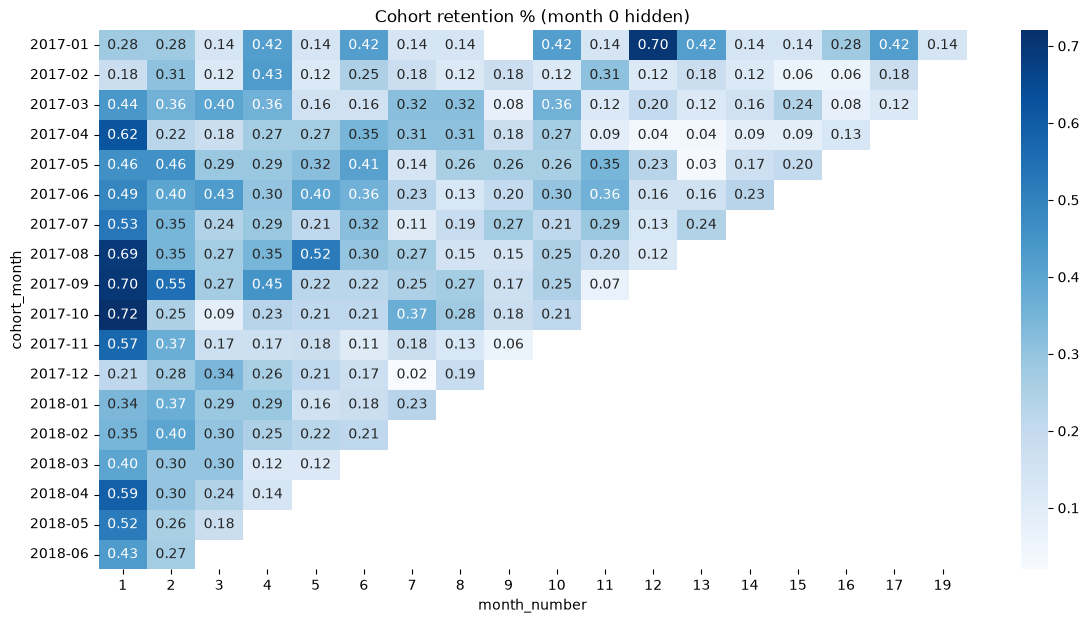

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
sns.heatmap(heatmap.drop(columns=0), annot=True, fmt=".2f", cmap="Blues")
plt.title("Cohort retention % (month 0 hidden)")
plt.show()

In [24]:
snapshot = clean_orders["order_purchase_timestamp"].max()

rfm = clean_orders.groupby("customer_unique_id").agg(
    last_order=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum")).reset_index()

rfm["recency_days"] = (snapshot - rfm["last_order"]).dt.days

# NTILE(5) equivalent: rank first so ties don't break qcut
rfm["r"] = pd.qcut(rfm["last_order"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["m"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["f"] = rfm["frequency"].apply(lambda x: 1 if x == 1 else (3 if x == 2 else 5))

def segment(row):
    if row.f >= 3 and row.r >= 4: return "Champions"
    if row.f >= 3 and row.r <= 3: return "Loyal - At Risk"
    if row.f == 1 and row.r >= 4 and row.m >= 4: return "New Big Spenders"
    if row.f == 1 and row.r >= 4: return "New Customers"
    if row.f == 1 and row.r <= 2 and row.m >= 4: return "At Risk - High Value"
    if row.f == 1 and row.r <= 2: return "Lost"
    return "Needs Attention"

rfm["segment"] = rfm.apply(segment, axis=1)

rfm_summary = (rfm.groupby("segment")
               .agg(customers=("customer_unique_id", "count"),
                    revenue=("monetary", "sum"),
                    avg_spend=("monetary", "mean"),
                    avg_days_since_last_order=("recency_days", "mean"))
               .round(1).sort_values("revenue", ascending=False))
print(rfm_summary)

                      customers    revenue  avg_spend  \
segment                                                 
New Big Spenders          14405  4353353.7      302.2   
At Risk - High Value      13784  4242069.8      307.8   
Needs Attention           18069  2737051.6      151.5   
Lost                      22563  1640483.2       72.7   
New Customers             21735  1585146.3       72.9   
Loyal - At Risk            1598   476292.2      298.1   
Champions                  1203   388065.0      322.6   

                      avg_days_since_last_order  
segment                                          
New Big Spenders                           90.4  
At Risk - High Value                      392.7  
Needs Attention                           218.9  
Lost                                      394.6  
New Customers                              88.8  
Loyal - At Risk                           318.3  
Champions                                  87.7  


In [25]:
df = clean_orders[clean_orders["order_delivered_customer_date"].notna()].merge(clean_reviews, on="order_id")
df["delivery_status"] = (df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]).map({True: "Late", False: "On time"})

# First order per customer
first = df.sort_values("order_purchase_timestamp").drop_duplicates("customer_unique_id")

# Repeat flag from all clean orders
orders_per_customer = clean_orders.groupby("customer_unique_id")["order_id"].nunique()
first["is_repeat"] = first["customer_unique_id"].map(orders_per_customer) > 1

delivery_impact = first.groupby("delivery_status").agg(
    customers=("customer_unique_id", "count"),
    avg_review=("review_score", "mean"),
    repeat_rate_pct=("is_repeat", lambda x: 100 * x.mean())).round(2)
print(delivery_impact)

                 customers  avg_review  repeat_rate_pct
delivery_status                                        
Late                  7447        2.56             2.51
On time              85299        4.29             3.05


In [26]:
from scipy.stats import chi2_contingency

table = pd.crosstab(first["delivery_status"], first["is_repeat"])
chi2, p, _, _ = chi2_contingency(table)
print("p-value:", p)

p-value: 0.009486589594305593


In [27]:
cohort.to_csv("cohort_py.csv", index=False)
rfm_summary.to_csv("rfm_summary_py.csv")
delivery_impact.to_csv("delivery_impact_py.csv")